# LSTM Model

## Ablation Study

Train: preprocessed_augmented_dataset_scaled.csv
Val:   validation_set_scaled.csv
Test:  test_set_scaled.csv
Train samples: 100000 | Val: 320 | Test: 330
Features: 19 | Classes: 10

Running variant: 0_baseline_full_model
Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - accuracy: 0.9008 - loss: 0.3174 - val_accuracy: 0.9375 - val_loss: 0.2270 - learning_rate: 0.0010
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9565 - loss: 0.1629 - val_accuracy: 0.9531 - val_loss: 0.1771 - learning_rate: 0.0010
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9647 - loss: 0.1386 - val_accuracy: 0.9500 - val_loss: 0.2066 - learning_rate: 0.0010
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9694 - loss: 0.1240 - val_accuracy: 0.9563 - val_loss: 0.2061 - learning_rate: 0.0010
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9732 - loss: 0.1092 - val_accuracy: 0.9469 - val_loss: 0.2406 - learning_rate: 0.0010
Epoch 6/40

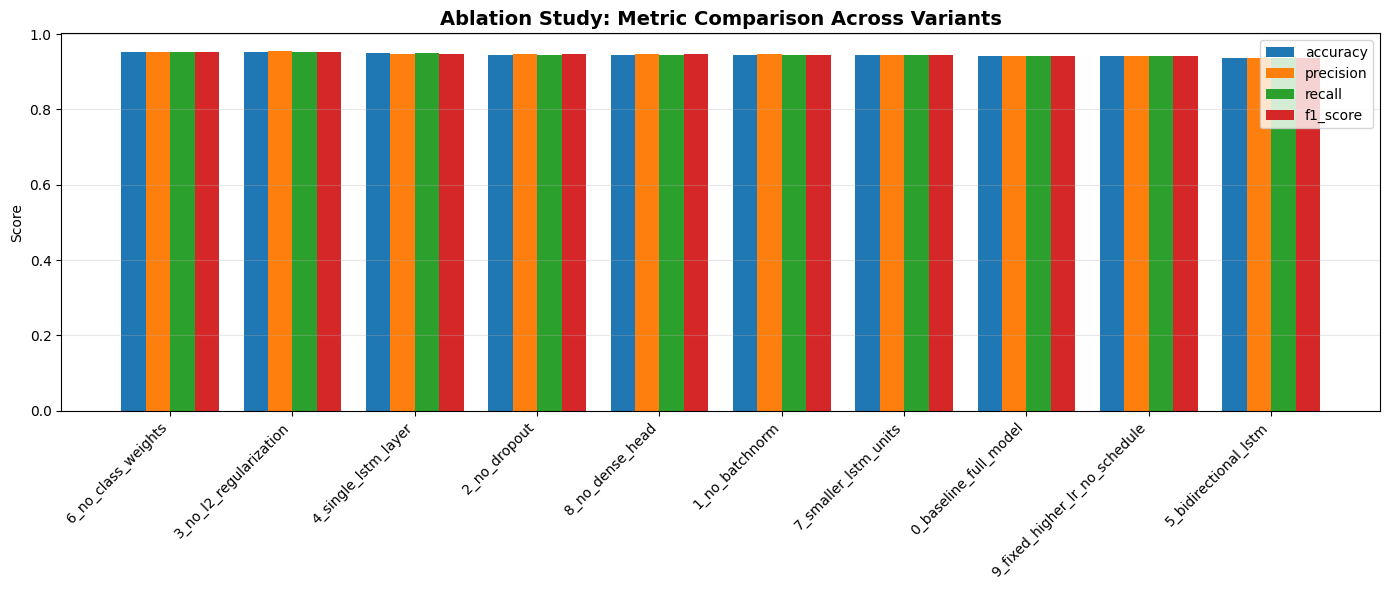

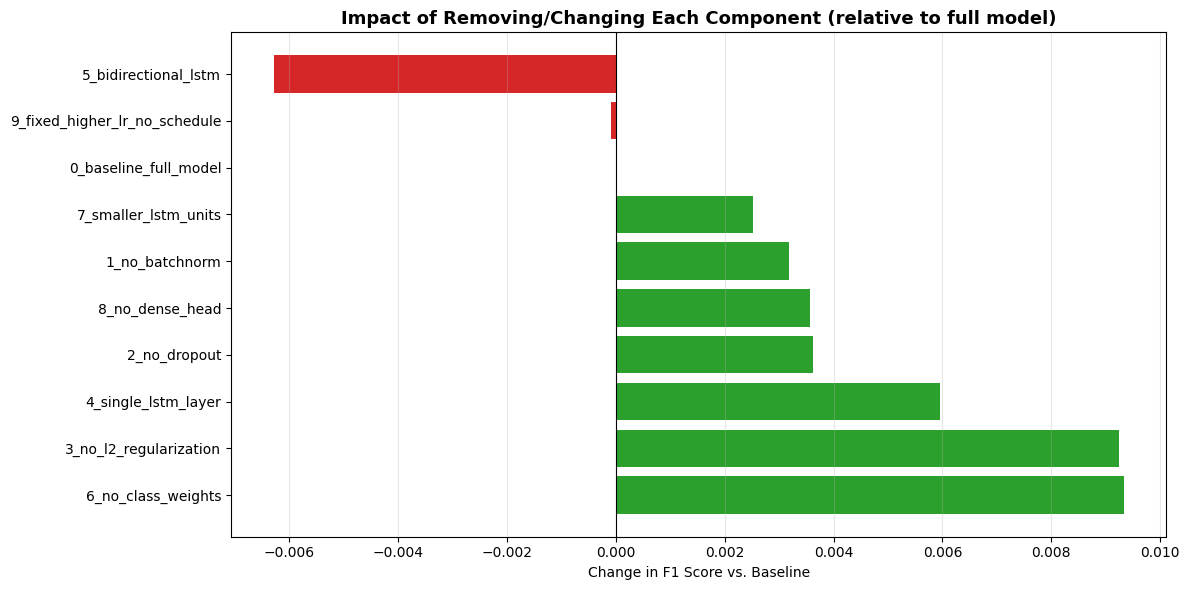

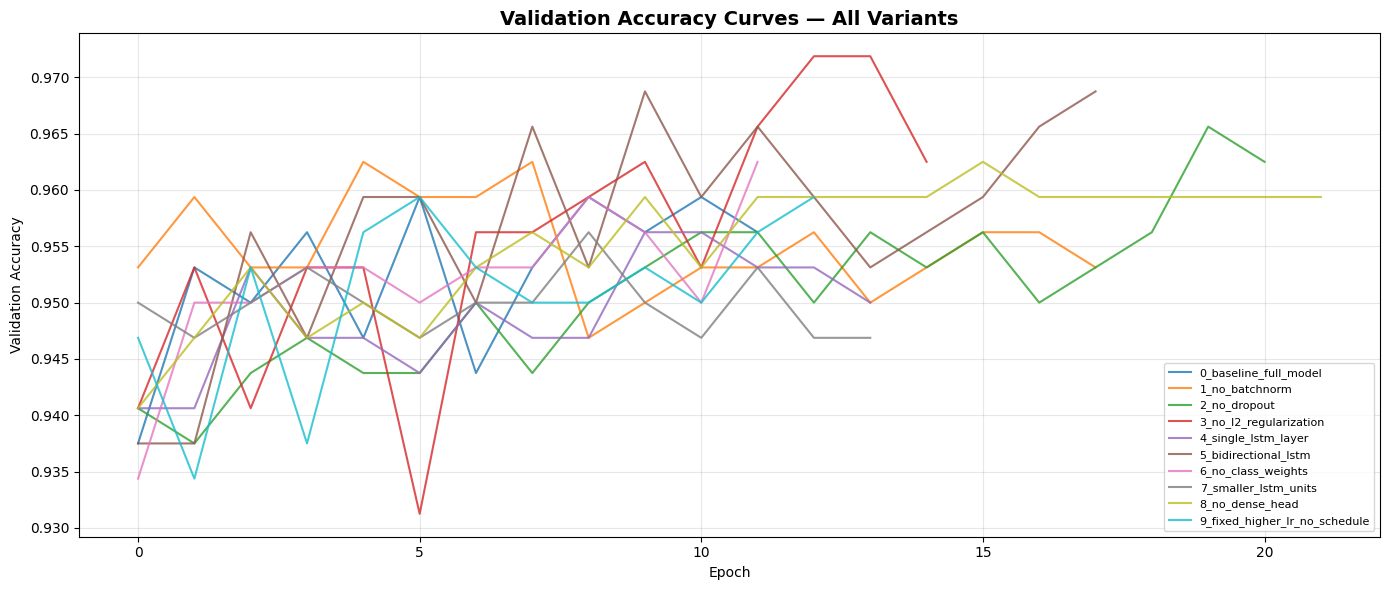


Saved plots: ablation_metric_comparison.png, ablation_delta_from_baseline.png, ablation_val_accuracy_curves.png

SUMMARY: Component impact (F1 drop when removed/changed, vs baseline)
                      variant  f1_delta_vs_baseline  trainable_params
         5_bidirectional_lstm             -0.006283            349514
9_fixed_higher_lr_no_schedule             -0.000091            146506
         7_smaller_lstm_units              0.002514             49098
               1_no_batchnorm              0.003185            145738
              8_no_dense_head              0.003576            122378
                 2_no_dropout              0.003615            146506
          4_single_lstm_layer              0.005948            101706
       3_no_l2_regularization              0.009252            146506
           6_no_class_weights              0.009330            146506

Most negative delta = component contributes most to performance when present.
Positive delta = removing/changing th

In [ ]:
# ============================================================
# ABLATION STUDY: LSTM FOR BEARING FAULT DETECTION
# Variants tested:
#   0. Full model (baseline)
#   1. No BatchNormalization
#   2. No Dropout
#   3. No L2 regularization
#   4. Single LSTM layer instead of stacked 2-layer
#   5. Bidirectional LSTM instead of unidirectional
#   6. No class weighting (imbalance handling removed)
#   7. Smaller LSTM units (64->32, 128->64)
#   8. No extra Dense head (drop post-LSTM dense layers)
#   9. Fixed higher learning rate, no ReduceLROnPlateau
# ============================================================

# !pip -q install tensorflow

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, BatchNormalization, Bidirectional
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

from google.colab import files
uploaded = files.upload()

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ============================================================
# LOAD DATA
# ============================================================

def find_file(keyword):
    for f in os.listdir():
        if keyword in f.lower():
            return f
    return None

train_file = find_file("augmented")
val_file = find_file("validation")
test_file = find_file("test")

print(f"Train: {train_file}")
print(f"Val:   {val_file}")
print(f"Test:  {test_file}")

train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

X_train_raw = train_df.iloc[:, :-1].values
y_train = train_df.iloc[:, -1].values

X_val_raw = val_df.iloc[:, :-1].values
y_val = val_df.iloc[:, -1].values

X_test_raw = test_df.iloc[:, :-1].values
y_test = test_df.iloc[:, -1].values

num_classes = len(np.unique(y_train))
y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_val_cat = to_categorical(y_val, num_classes=num_classes)
y_test_cat = to_categorical(y_test, num_classes=num_classes)

# Reshape for LSTM: (samples, timesteps, features)
X_train = X_train_raw.reshape((X_train_raw.shape[0], 1, X_train_raw.shape[1]))
X_val = X_val_raw.reshape((X_val_raw.shape[0], 1, X_val_raw.shape[1]))
X_test = X_test_raw.reshape((X_test_raw.shape[0], 1, X_test_raw.shape[1]))

n_features = X_train.shape[2]

# Class weights for imbalance (used unless the variant explicitly disables it)
classes = np.unique(y_train)
class_weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, class_weights))

print(f"Train samples: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")
print(f"Features: {n_features} | Classes: {num_classes}")


# ============================================================
# CONFIGURABLE MODEL BUILDER
# ============================================================

DEFAULT_CONFIG = {
    "name": "baseline_full_model",
    "use_batchnorm": True,
    "use_dropout": True,
    "dropout_rate": 0.3,
    "use_l2": True,
    "l2_value": 1e-4,
    "num_lstm_layers": 2,          # 1 or 2
    "lstm_units": [64, 128],       # units per LSTM layer (len must match num_lstm_layers)
    "bidirectional": False,
    "use_dense_head": True,        # the two Dense(128)/Dense(64) layers after LSTM
    "dense_units": [128, 64],
    "use_class_weights": True,
    "learning_rate": 0.001,
    "use_lr_schedule": True,       # ReduceLROnPlateau
}


def reg(cfg):
    return l2(cfg["l2_value"]) if cfg["use_l2"] else None


def build_model(cfg):
    layers = [Input(shape=(1, n_features))]

    for i in range(cfg["num_lstm_layers"]):
        units = cfg["lstm_units"][i]
        return_seq = (i < cfg["num_lstm_layers"] - 1)  # only last LSTM returns False
        lstm_layer = LSTM(
            units,
            return_sequences=return_seq,
            activation='tanh',
            kernel_regularizer=reg(cfg),
        )
        if cfg["bidirectional"]:
            lstm_layer = Bidirectional(lstm_layer)
        layers.append(lstm_layer)

        if cfg["use_batchnorm"]:
            layers.append(BatchNormalization())
        if cfg["use_dropout"]:
            layers.append(Dropout(cfg["dropout_rate"]))

    if cfg["use_dense_head"]:
        for units in cfg["dense_units"]:
            layers.append(Dense(units, activation='relu', kernel_regularizer=reg(cfg)))
            if cfg["use_dropout"]:
                layers.append(Dropout(cfg["dropout_rate"]))

    layers.append(Dense(num_classes, activation='softmax'))

    model = Sequential(layers)
    model.compile(
        optimizer=Adam(learning_rate=cfg["learning_rate"]),
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model


def get_callbacks(cfg):
    callbacks = [EarlyStopping(patience=10, restore_best_weights=True, monitor='val_loss')]
    if cfg["use_lr_schedule"]:
        callbacks.append(ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-6))
    return callbacks


def run_experiment(cfg, epochs=40, batch_size=128, verbose=0):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    model = build_model(cfg)
    cw = class_weight_dict if cfg["use_class_weights"] else None

    history = model.fit(
        X_train, y_train_cat,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(X_val, y_val_cat),
        callbacks=get_callbacks(cfg),
        class_weight=cw,
        verbose=verbose,
    )

    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)

    metrics = {
        "variant": cfg["name"],
        "accuracy": accuracy_score(y_test, y_pred_classes),
        "precision": precision_score(y_test, y_pred_classes, average='weighted', zero_division=0),
        "recall": recall_score(y_test, y_pred_classes, average='weighted', zero_division=0),
        "f1_score": f1_score(y_test, y_pred_classes, average='weighted', zero_division=0),
        "epochs_run": len(history.history['accuracy']),
        "final_val_accuracy": history.history['val_accuracy'][-1],
        "final_val_loss": history.history['val_loss'][-1],
        "trainable_params": model.count_params(),
    }
    return metrics, history


# ============================================================
# DEFINE ABLATION VARIANTS
# ============================================================

def make_cfg(overrides):
    cfg = dict(DEFAULT_CONFIG)
    cfg.update(overrides)
    return cfg


ablation_variants = [
    make_cfg({"name": "0_baseline_full_model"}),

    make_cfg({"name": "1_no_batchnorm", "use_batchnorm": False}),

    make_cfg({"name": "2_no_dropout", "use_dropout": False}),

    make_cfg({"name": "3_no_l2_regularization", "use_l2": False}),

    make_cfg({
        "name": "4_single_lstm_layer",
        "num_lstm_layers": 1,
        "lstm_units": [128],
    }),

    make_cfg({"name": "5_bidirectional_lstm", "bidirectional": True}),

    make_cfg({"name": "6_no_class_weights", "use_class_weights": False}),

    make_cfg({
        "name": "7_smaller_lstm_units",
        "lstm_units": [32, 64],
    }),

    make_cfg({"name": "8_no_dense_head", "use_dense_head": False}),

    make_cfg({
        "name": "9_fixed_higher_lr_no_schedule",
        "learning_rate": 0.005,
        "use_lr_schedule": False,
    }),
]


# ============================================================
# RUN ALL EXPERIMENTS
# ============================================================

results = []
histories = {}

for cfg in ablation_variants:
    print("\n" + "=" * 70)
    print(f"Running variant: {cfg['name']}")
    print("=" * 70)
    metrics, history = run_experiment(cfg, epochs=40, batch_size=128, verbose=1)
    results.append(metrics)
    histories[cfg["name"]] = history.history
    print(f"  -> Accuracy: {metrics['accuracy']:.4f} | F1: {metrics['f1_score']:.4f} "
          f"| Epochs: {metrics['epochs_run']} | Params: {metrics['trainable_params']:,}")

results_df = pd.DataFrame(results).sort_values("f1_score", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("ABLATION STUDY RESULTS (sorted by F1 score)")
print("=" * 70)
print(results_df.to_string(index=False))

results_df.to_csv("ablation_results.csv", index=False)
with open("ablation_histories.json", "w") as f:
    json.dump(histories, f)

print("\nSaved: ablation_results.csv, ablation_histories.json")


# ============================================================
# VISUALIZATIONS
# ============================================================

baseline_row = results_df[results_df["variant"] == "0_baseline_full_model"].iloc[0]

# --- Bar chart: metric comparison across variants ---
plt.figure(figsize=(14, 6))
metrics_to_plot = ["accuracy", "precision", "recall", "f1_score"]
x = np.arange(len(results_df))
width = 0.2

for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + i * width, results_df[metric], width, label=metric)

plt.xticks(x + width * 1.5, results_df["variant"], rotation=45, ha='right')
plt.ylabel("Score")
plt.title("Ablation Study: Metric Comparison Across Variants", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("ablation_metric_comparison.png", dpi=150)
plt.show()

# --- Delta-from-baseline chart (the key ablation insight) ---
plt.figure(figsize=(12, 6))
delta_f1 = results_df["f1_score"] - baseline_row["f1_score"]
colors = ['#d62728' if v < 0 else '#2ca02c' for v in delta_f1]
plt.barh(results_df["variant"], delta_f1, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Change in F1 Score vs. Baseline")
plt.title("Impact of Removing/Changing Each Component (relative to full model)",
          fontsize=13, fontweight='bold')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("ablation_delta_from_baseline.png", dpi=150)
plt.show()

# --- Training curves overlay for accuracy ---
plt.figure(figsize=(14, 6))
for name, hist in histories.items():
    plt.plot(hist['val_accuracy'], label=name, alpha=0.8)
plt.title("Validation Accuracy Curves — All Variants", fontsize=14, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend(fontsize=8, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("ablation_val_accuracy_curves.png", dpi=150)
plt.show()

print("\nSaved plots: ablation_metric_comparison.png, ablation_delta_from_baseline.png, "
      "ablation_val_accuracy_curves.png")

# ============================================================
# SUMMARY: WHICH COMPONENTS MATTER MOST
# ============================================================
print("\n" + "=" * 70)
print("SUMMARY: Component impact (F1 drop when removed/changed, vs baseline)")
print("=" * 70)
summary = results_df.copy()
summary["f1_delta_vs_baseline"] = summary["f1_score"] - baseline_row["f1_score"]
summary = summary[summary["variant"] != "0_baseline_full_model"]
summary = summary.sort_values("f1_delta_vs_baseline")
print(summary[["variant", "f1_delta_vs_baseline", "trainable_params"]].to_string(index=False))